# <font color="gold">0-2. Extract U of Waterloo Course Review Data</font>

## <font color='cornflowerblue'>Course review - Dataset Info</font>

-----------------------------------------
Category:  &ensp;&emsp; Course review  
Source:    &ensp; &ensp;&ensp; &ensp;  Course Reviews University of Waterloo   (N = 14810)  
URL:     &ensp; &ensp; &ensp; &ensp;  &ensp;  https://www.kaggle.com/datasets/anthonysusevski/course-reviews-university-of-waterloo   
Lisence:  &ensp; &ensp; &ensp;  CC0: Public Domain  
“The reviews were entirely sourced from uwflow.com and the code that was used to webscrape the data is found at https://github.com/asusevski/course_reviews

-----------------------------------------

In [1]:
import pandas as pd

file = '../../data/0_raw/data2_UWaterloo_course_data_clean.csv' 

outfilename = '../../data/1_processed/2_Uwaterloo_course_reviews.csv'

print(f'Input: \n          {file}\n\nOutput:   {outfilename}')

Input: 
          ../../data/0_raw/data2_UWaterloo_course_data_clean.csv

Output:   ../../data/1_processed/2_Uwaterloo_course_reviews.csv


In [2]:
output = pd.read_csv(file, dtype=str)

print(len(output))
output = output.drop_duplicates(keep='first')
print(len(output))

output


14838
14832


,course_code,course_title,num_ratings,useful,easy,liked,num_reviews,reviews,course_rating,course_rating_int
0,CS 115,Introduction to Computer Science 1,2111,21%,10%,23%,86,go to office hours and practice,liked course,1.0
1,CS 115,Introduction to Computer Science 1,2111,21%,10%,23%,86,One of my least favourite courses. Although th...,disliked course,0.0
2,CS 115,Introduction to Computer Science 1,2111,21%,10%,23%,86,It starts with a very low pace but after midte...,disliked course,0.0
3,CS 115,Introduction to Computer Science 1,2111,21%,10%,23%,86,Took this in 2018 with no programming experien...,liked course,1.0
4,CS 115,Introduction to Computer Science 1,2111,21%,10%,23%,86,I loved everything about cs 115. Great instruc...,liked course,1.0
...,...,...,...,...,...,...,...,...,...,...
14833,ASL 102R,American Sign Language 2,1,100%,75%,100%,1,Took this online with Georgia Whalen. As it wa...,liked course,1.0
14834,CS 136L,Tools and Techniques for Software Development,1,100%,100%,100%,1,I either designed or helped design the majorit...,liked course,1.0
14835,AFM 417,Special Topics in Accounting,0,NaN,NaN,NaN,1,Topic 3: Intro to Data Analytics,NaN,NaN
14836,ECON 472,Senior Honours Essay,0,100%,0%,NaN,1,Not sure if I liked this course yet. Definitel...,NaN,NaN


In [3]:
output = output.reset_index()
output = output.rename(columns={'index':'entry_idx', 'reviews':'review_text', 'course_title':'course_id', 'course_rating_int':'rating', 'course_rating':'rating_category'}).fillna('')

print(len(output), len(output.course_id.unique()))

print(list(output.columns.values)) 

output

14832 1730
['entry_idx', 'course_code', 'course_id', 'num_ratings', 'useful', 'easy', 'liked', 'num_reviews', 'review_text', 'rating_category', 'rating']


,entry_idx,course_code,course_id,num_ratings,useful,easy,liked,num_reviews,review_text,rating_category,rating
0,0,CS 115,Introduction to Computer Science 1,2111,21%,10%,23%,86,go to office hours and practice,liked course,1.0
1,1,CS 115,Introduction to Computer Science 1,2111,21%,10%,23%,86,One of my least favourite courses. Although th...,disliked course,0.0
2,2,CS 115,Introduction to Computer Science 1,2111,21%,10%,23%,86,It starts with a very low pace but after midte...,disliked course,0.0
3,3,CS 115,Introduction to Computer Science 1,2111,21%,10%,23%,86,Took this in 2018 with no programming experien...,liked course,1.0
4,4,CS 115,Introduction to Computer Science 1,2111,21%,10%,23%,86,I loved everything about cs 115. Great instruc...,liked course,1.0
...,...,...,...,...,...,...,...,...,...,...,...
14827,14833,ASL 102R,American Sign Language 2,1,100%,75%,100%,1,Took this online with Georgia Whalen. As it wa...,liked course,1.0
14828,14834,CS 136L,Tools and Techniques for Software Development,1,100%,100%,100%,1,I either designed or helped design the majorit...,liked course,1.0
14829,14835,AFM 417,Special Topics in Accounting,0,,,,1,Topic 3: Intro to Data Analytics,,
14830,14836,ECON 472,Senior Honours Essay,0,100%,0%,,1,Not sure if I liked this course yet. Definitel...,,


In [4]:
output.filter(regex='rating_|rating$').drop_duplicates(keep='first')

,rating_category,rating
0,liked course,1.0
1,disliked course,0.0
50,,


In [5]:
output.loc[output.rating.str.len()==0]

,entry_idx,course_code,course_id,num_ratings,useful,easy,liked,num_reviews,review_text,rating_category,rating
50,50,CS 115,Introduction to Computer Science 1,2111,21%,10%,23%,86,"Thanks to Keiko Katsuragawa, the prof who does...",,
70,70,CS 115,Introduction to Computer Science 1,2111,21%,10%,23%,86,Never taken anything even remotely related and...,,
81,81,CS 115,Introduction to Computer Science 1,2111,21%,10%,23%,86,"hard at first, will get use to it",,
248,248,MATH 135,Algebra for Honours Mathematics,1186,84%,41%,78%,253,Interesting but challenging. I should've done ...,,
291,291,MATH 135,Algebra for Honours Mathematics,1186,84%,41%,78%,253,Hard to get used to the way of thinking at first.,,
...,...,...,...,...,...,...,...,...,...,...,...
14652,14658,SYDE 302,Seminar,2,0%,0%,50%,1,This is the same course as SYDE 362. Difficult...,,
14779,14785,REC 356,Leisure and Community,1,0%,100%,0%,1,easy course with reflections and group project...,,
14829,14835,AFM 417,Special Topics in Accounting,0,,,,1,Topic 3: Intro to Data Analytics,,
14830,14836,ECON 472,Senior Honours Essay,0,100%,0%,,1,Not sure if I liked this course yet. Definitel...,,


,rating,count
2,,222
1,0.0,4826
0,1.0,9784


<Axes: xlabel='Count', ylabel='rating'>

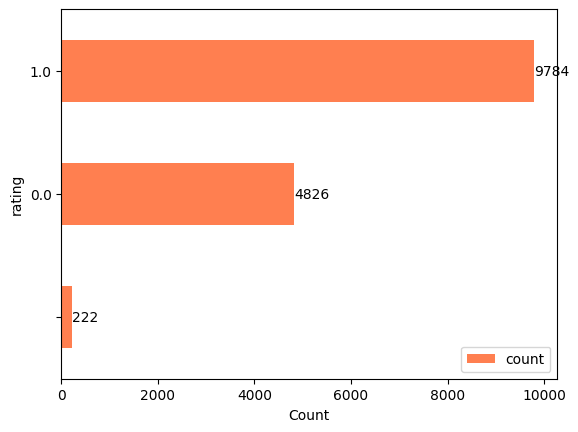

In [6]:
rating_df = output.rating.value_counts().reset_index().sort_values(by='rating', ascending=True)

display(rating_df)

ax1 = rating_df.plot.barh(x='rating', y='count', xlabel='Count', color='coral', table=False)
ax1.bar_label(ax1.containers[0]) 
ax1

In [7]:
print(len(output))
output = output.loc[(output.review_text.str.len() > 0) & (~output.review_text.str.lower().isin(['no comment', 'no comments'])) & (~output.review_text.str.fullmatch(r'([.]+|[,]+)'))]
print(len(output))

output

14832
14810


,entry_idx,course_code,course_id,num_ratings,useful,easy,liked,num_reviews,review_text,rating_category,rating
0,0,CS 115,Introduction to Computer Science 1,2111,21%,10%,23%,86,go to office hours and practice,liked course,1.0
1,1,CS 115,Introduction to Computer Science 1,2111,21%,10%,23%,86,One of my least favourite courses. Although th...,disliked course,0.0
2,2,CS 115,Introduction to Computer Science 1,2111,21%,10%,23%,86,It starts with a very low pace but after midte...,disliked course,0.0
3,3,CS 115,Introduction to Computer Science 1,2111,21%,10%,23%,86,Took this in 2018 with no programming experien...,liked course,1.0
4,4,CS 115,Introduction to Computer Science 1,2111,21%,10%,23%,86,I loved everything about cs 115. Great instruc...,liked course,1.0
...,...,...,...,...,...,...,...,...,...,...,...
14827,14833,ASL 102R,American Sign Language 2,1,100%,75%,100%,1,Took this online with Georgia Whalen. As it wa...,liked course,1.0
14828,14834,CS 136L,Tools and Techniques for Software Development,1,100%,100%,100%,1,I either designed or helped design the majorit...,liked course,1.0
14829,14835,AFM 417,Special Topics in Accounting,0,,,,1,Topic 3: Intro to Data Analytics,,
14830,14836,ECON 472,Senior Honours Essay,0,100%,0%,,1,Not sure if I liked this course yet. Definitel...,,


In [8]:
output.loc[output.review_text.str.fullmatch(r'([.]+|[,]+)')]

,entry_idx,course_code,course_id,num_ratings,useful,easy,liked,num_reviews,review_text,rating_category,rating


In [9]:
xx = output.copy()
xx = xx.loc[(xx.rating != '') & (xx.easy != '')]
xx.easy = xx.easy.str.replace('%','').astype('float64')
xx = xx[['easy','rating']].value_counts().reset_index().sort_values(by=['easy'], ascending=False)
pivot = xx.pivot_table(index='easy', columns='rating', values='count')
pivot.loc[:,'TOTAL'] = pivot.sum(axis=1)
pivot

rating,0.0,1.0,TOTAL
easy,,,
0.0,56.0,81.0,137.0
3.0,1.0,1.0,2.0
4.0,3.0,4.0,7.0
5.0,11.0,11.0,22.0
6.0,6.0,10.0,16.0
...,...,...,...
96.0,5.0,47.0,52.0
97.0,30.0,51.0,81.0
98.0,4.0,25.0,29.0


,rating,count
2,,221
1,0.0,4811
0,1.0,9778


<Axes: xlabel='Count', ylabel='rating'>

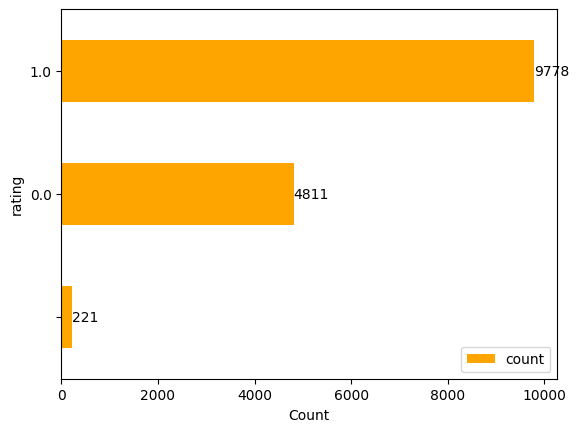

In [10]:
overall_ratingdf = output.rating.value_counts().reset_index().sort_values(by='rating', ascending=True)

display(overall_ratingdf)

ax3 = overall_ratingdf.plot.barh(x='rating', y='count', xlabel='Count', color='orange', table=False)
ax3.bar_label(ax3.containers[0]) 
ax3

## <font color='gold'>Make unique IDs</font>

In [11]:
output.loc[:,'source'] = f'data2_{len(output)}'
output

/tmp/ipykernel_45574/3211010531.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  output.loc[:,'source'] = f'data2_{len(output)}'


,entry_idx,course_code,course_id,num_ratings,useful,easy,liked,num_reviews,review_text,rating_category,rating,source
0,0,CS 115,Introduction to Computer Science 1,2111,21%,10%,23%,86,go to office hours and practice,liked course,1.0,data2_14810
1,1,CS 115,Introduction to Computer Science 1,2111,21%,10%,23%,86,One of my least favourite courses. Although th...,disliked course,0.0,data2_14810
2,2,CS 115,Introduction to Computer Science 1,2111,21%,10%,23%,86,It starts with a very low pace but after midte...,disliked course,0.0,data2_14810
3,3,CS 115,Introduction to Computer Science 1,2111,21%,10%,23%,86,Took this in 2018 with no programming experien...,liked course,1.0,data2_14810
4,4,CS 115,Introduction to Computer Science 1,2111,21%,10%,23%,86,I loved everything about cs 115. Great instruc...,liked course,1.0,data2_14810
...,...,...,...,...,...,...,...,...,...,...,...,...
14827,14833,ASL 102R,American Sign Language 2,1,100%,75%,100%,1,Took this online with Georgia Whalen. As it wa...,liked course,1.0,data2_14810
14828,14834,CS 136L,Tools and Techniques for Software Development,1,100%,100%,100%,1,I either designed or helped design the majorit...,liked course,1.0,data2_14810
14829,14835,AFM 417,Special Topics in Accounting,0,,,,1,Topic 3: Intro to Data Analytics,,,data2_14810
14830,14836,ECON 472,Senior Honours Essay,0,100%,0%,,1,Not sure if I liked this course yet. Definitel...,,,data2_14810


In [12]:
idcols = ['source', 'entry_idx', 'course_id']

for each in idcols:
    if each == 'source':
        output.loc[:,f'{each}_rank'] = output.source.str[4]
    else:
        output.loc[:,f'{each}_rank'] = output[each].rank(method='dense').astype(int)
        
output

/tmp/ipykernel_45574/3467851034.py:5: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  output.loc[:,f'{each}_rank'] = output.source.str[4]
/tmp/ipykernel_45574/3467851034.py:7: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  output.loc[:,f'{each}_rank'] = output[each].rank(method='dense').astype(int)
/tmp/ipykernel_45574/3467851034.py:7: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the docum

,entry_idx,course_code,course_id,num_ratings,useful,easy,liked,num_reviews,review_text,rating_category,rating,source,source_rank,entry_idx_rank,course_id_rank
0,0,CS 115,Introduction to Computer Science 1,2111,21%,10%,23%,86,go to office hours and practice,liked course,1.0,data2_14810,2,1,794
1,1,CS 115,Introduction to Computer Science 1,2111,21%,10%,23%,86,One of my least favourite courses. Although th...,disliked course,0.0,data2_14810,2,2,794
2,2,CS 115,Introduction to Computer Science 1,2111,21%,10%,23%,86,It starts with a very low pace but after midte...,disliked course,0.0,data2_14810,2,3,794
3,3,CS 115,Introduction to Computer Science 1,2111,21%,10%,23%,86,Took this in 2018 with no programming experien...,liked course,1.0,data2_14810,2,4,794
4,4,CS 115,Introduction to Computer Science 1,2111,21%,10%,23%,86,I loved everything about cs 115. Great instruc...,liked course,1.0,data2_14810,2,5,794
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
14827,14833,ASL 102R,American Sign Language 2,1,100%,75%,100%,1,Took this online with Georgia Whalen. As it wa...,liked course,1.0,data2_14810,2,14806,63
14828,14834,CS 136L,Tools and Techniques for Software Development,1,100%,100%,100%,1,I either designed or helped design the majorit...,liked course,1.0,data2_14810,2,14807,1676
14829,14835,AFM 417,Special Topics in Accounting,0,,,,1,Topic 3: Intro to Data Analytics,,,data2_14810,2,14808,1528
14830,14836,ECON 472,Senior Honours Essay,0,100%,0%,,1,Not sure if I liked this course yet. Definitel...,,,data2_14810,2,14809,1461


In [13]:
output.insert(loc=0, column='id', value=output.filter(regex='_rank').map(str).apply('_'.join, axis=1))
output.loc[:,'type'] = 'course review'

if len(output.id.unique())==len(output):
    print("\033[32mAll good!\n\033[0m")
    output = output.drop(columns=[i for i in output.columns.values if '_rank' in i])
else:
    display(output.loc[output.id.duplicated(keep='first')].sort_values(by='id'))
    raise ValueError("ids not unique, check!!!!")

output

All good!



/tmp/ipykernel_45574/2206326164.py:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  output.loc[:,'type'] = 'course review'


,id,entry_idx,course_code,course_id,num_ratings,useful,easy,liked,num_reviews,review_text,rating_category,rating,source,type
0,2_1_794,0,CS 115,Introduction to Computer Science 1,2111,21%,10%,23%,86,go to office hours and practice,liked course,1.0,data2_14810,course review
1,2_2_794,1,CS 115,Introduction to Computer Science 1,2111,21%,10%,23%,86,One of my least favourite courses. Although th...,disliked course,0.0,data2_14810,course review
2,2_3_794,2,CS 115,Introduction to Computer Science 1,2111,21%,10%,23%,86,It starts with a very low pace but after midte...,disliked course,0.0,data2_14810,course review
3,2_4_794,3,CS 115,Introduction to Computer Science 1,2111,21%,10%,23%,86,Took this in 2018 with no programming experien...,liked course,1.0,data2_14810,course review
4,2_5_794,4,CS 115,Introduction to Computer Science 1,2111,21%,10%,23%,86,I loved everything about cs 115. Great instruc...,liked course,1.0,data2_14810,course review
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
14827,2_14806_63,14833,ASL 102R,American Sign Language 2,1,100%,75%,100%,1,Took this online with Georgia Whalen. As it wa...,liked course,1.0,data2_14810,course review
14828,2_14807_1676,14834,CS 136L,Tools and Techniques for Software Development,1,100%,100%,100%,1,I either designed or helped design the majorit...,liked course,1.0,data2_14810,course review
14829,2_14808_1528,14835,AFM 417,Special Topics in Accounting,0,,,,1,Topic 3: Intro to Data Analytics,,,data2_14810,course review
14830,2_14809_1461,14836,ECON 472,Senior Honours Essay,0,100%,0%,,1,Not sure if I liked this course yet. Definitel...,,,data2_14810,course review


In [14]:
output.loc[output.course_id=='']

,id,entry_idx,course_code,course_id,num_ratings,useful,easy,liked,num_reviews,review_text,rating_category,rating,source,type


<br>

## <font color='gold'>Write output</font>

In [15]:
print(output.shape)
output.to_csv(outfilename, index=True)
print(f'\n\033[33mCombined file written to {outfilename} :)\n')

(14810, 14)

Combined file written to ../../data/1_processed/2_Uwaterloo_course_reviews.csv :)

